
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona - Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>

# Minería de Datos con Dataset Iris

En esta actividad se aplica el mismo proceso de minería de datos usando el dataset `Iris.csv`.

El objetivo es realizar limpieza, transformación, análisis exploratorio, aplicación de K-Means, justificación del número de clústeres e interpretación final de los resultados.

In [ ]:
# Importar librerías principales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from google.colab import files

sns.set(style="whitegrid")

# Subir archivo Iris.csv
uploaded = files.upload()

# Cargar dataset
df = pd.read_csv("Iris.csv")

# Mostrar primeras filas
df.head()

Saving Iris.csv to Iris.csv


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Ver tamaño del dataset
print("Filas y columnas:", df.shape)

# Información general
df.info()

# Revisar valores nulos
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Revisar datos duplicados
print("\nFilas duplicadas:", df.duplicated().sum())

# Estadísticas descriptivas
df.describe()

Filas y columnas: (150, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB

Valores nulos por columna:
Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Filas duplicadas: 0


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


# Preguntas y respuestas: Carga de datos

## 1. ¿Cuántas filas y columnas tiene el conjunto de datos?

El dataset Iris tiene **150 filas y 6 columnas**. Cada fila representa una flor y cada columna contiene información sobre sus medidas o especie.

## 2. ¿Qué tipo de variables contiene?

El conjunto de datos contiene variables numéricas y categóricas.

Las variables numéricas son:

- `SepalLengthCm`
- `SepalWidthCm`
- `PetalLengthCm`
- `PetalWidthCm`

La variable categórica es:

- `Species`

También contiene la columna `Id`, que funciona como identificador.

# Limpieza y transformación de datos

En esta etapa se eliminan columnas que no aportan al análisis, se revisan valores nulos y se seleccionan las variables numéricas para aplicar K-Means.

In [ ]:
# Crear una copia del dataset original
df_limpio = df.copy()

# Eliminar columna Id porque solo es un identificador
df_limpio = df_limpio.drop(columns=["Id"])

# Verificar resultado
df_limpio.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
# Seleccionar variables numéricas para K-Means
variables_numericas = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

X = df_limpio[variables_numericas]

# Estandarizar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Datos escalados correctamente.")

Datos escalados correctamente.


# Preguntas y respuestas: Limpieza y transformación

## 1. ¿Por qué es importante eliminar columnas irrelevantes?

Es importante eliminar columnas irrelevantes porque pueden afectar el análisis y el resultado del modelo. En este caso, la columna `Id` solo identifica cada registro, pero no aporta información útil sobre las características de la flor. Si se incluye en K-Means, puede alterar la formación de los clústeres.

## 2. ¿Qué ventaja ofrece la estandarización antes de K-Means?

La estandarización permite que todas las variables tengan una escala similar. Esto es importante porque K-Means usa distancias para formar grupos. Si una variable tiene valores más grandes que otra, puede influir demasiado en el resultado. Al estandarizar, todas las variables tienen una participación más equilibrada.

# Análisis Exploratorio de Datos — EDA

En esta sección se analizan las características principales del dataset Iris mediante gráficas, conteos y relaciones entre variables.

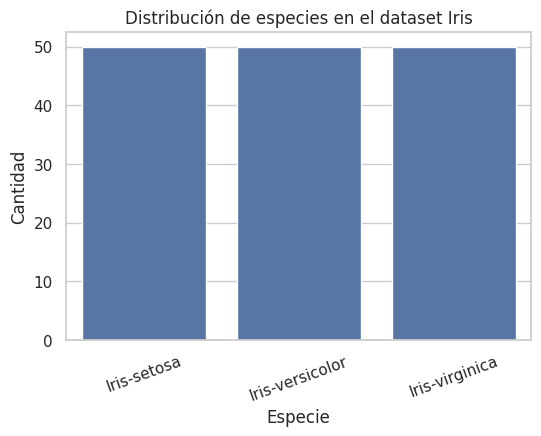

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="Species", data=df_limpio)
plt.title("Distribución de especies en el dataset Iris")
plt.xlabel("Especie")
plt.ylabel("Cantidad")
plt.xticks(rotation=20)
plt.show()

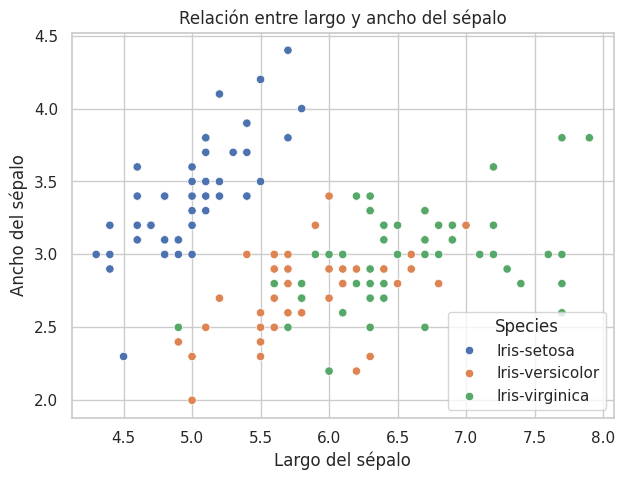

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    x="SepalLengthCm",
    y="SepalWidthCm",
    hue="Species",
    data=df_limpio
)
plt.title("Relación entre largo y ancho del sépalo")
plt.xlabel("Largo del sépalo")
plt.ylabel("Ancho del sépalo")
plt.show()

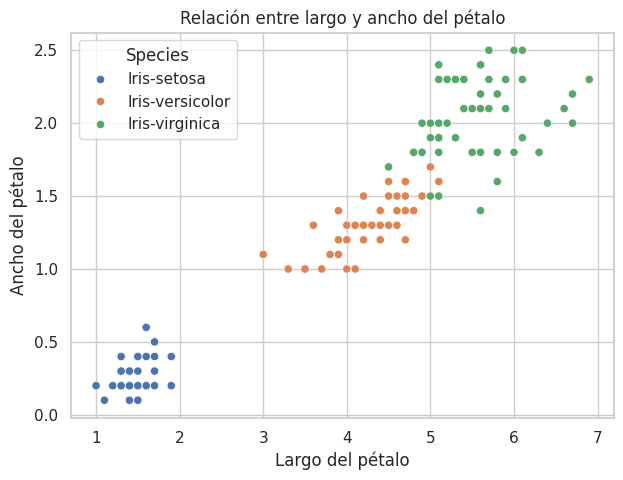

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    data=df_limpio
)
plt.title("Relación entre largo y ancho del pétalo")
plt.xlabel("Largo del pétalo")
plt.ylabel("Ancho del pétalo")
plt.show()

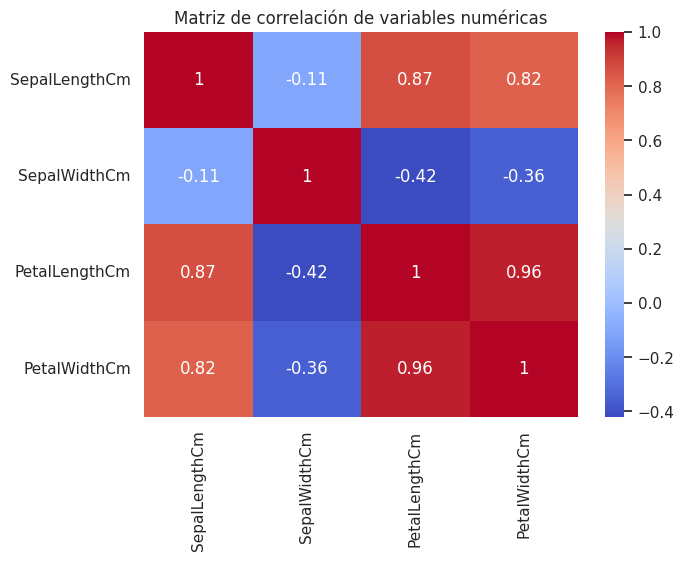

In [ ]:
plt.figure(figsize=(7,5))
sns.heatmap(
    df_limpio[variables_numericas].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Matriz de correlación de variables numéricas")
plt.show()

# Preguntas y respuestas: Análisis exploratorio

## 1. ¿Qué relación visual se observa entre las variables del pétalo?

Se observa una relación positiva entre el largo y el ancho del pétalo. Cuando el largo del pétalo aumenta, también suele aumentar el ancho. Además, estas variables permiten separar visualmente mejor las especies de Iris.

## 2. ¿Existen grupos naturales o concentraciones visibles?

Sí. En las gráficas se observan grupos naturales. La especie `Iris-setosa` se separa claramente de las demás, especialmente usando las variables del pétalo. Las especies `Iris-versicolor` e `Iris-virginica` presentan mayor cercanía entre ellas, por lo que pueden mezclarse parcialmente.

# Aplicación de K-Means

En esta sección se utiliza el algoritmo K-Means para agrupar las flores según sus características numéricas.

Para elegir el número adecuado de clústeres se utiliza el método del codo y también se calcula el índice de silueta.

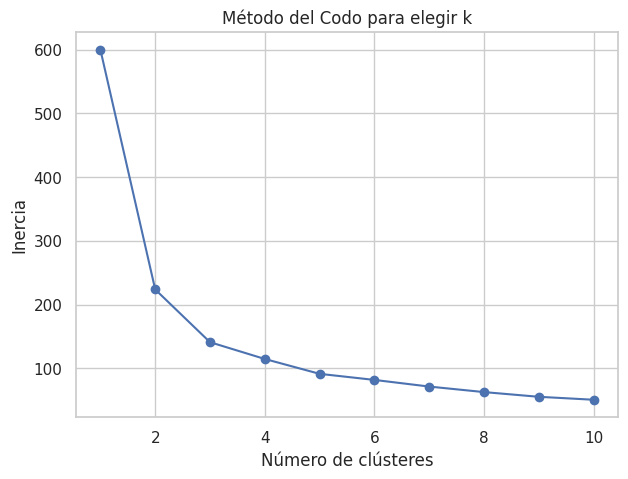

In [ ]:
inertia = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(7,5))
plt.plot(range(1, 11), inertia, marker="o")
plt.title("Método del Codo para elegir k")
plt.xlabel("Número de clústeres")
plt.ylabel("Inercia")
plt.grid(True)
plt.show()

k = 2, Silhouette Score = 0.5802
k = 3, Silhouette Score = 0.4590
k = 4, Silhouette Score = 0.3853
k = 5, Silhouette Score = 0.3473
k = 6, Silhouette Score = 0.3407
k = 7, Silhouette Score = 0.3288
k = 8, Silhouette Score = 0.3404
k = 9, Silhouette Score = 0.3427
k = 10, Silhouette Score = 0.3404


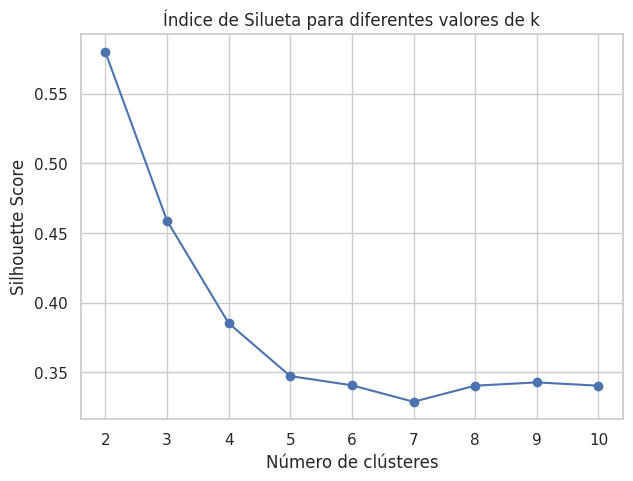

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k = {k}, Silhouette Score = {score:.4f}")

plt.figure(figsize=(7,5))
plt.plot(range(2, 11), silhouette_scores, marker="o")
plt.title("Índice de Silueta para diferentes valores de k")
plt.xlabel("Número de clústeres")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

In [ ]:
# Aplicar K-Means con 3 clústeres
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df_limpio["Cluster"] = kmeans.fit_predict(X_scaled)

# Mostrar primeras filas con clúster asignado
df_limpio.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Cluster
0,5.1,3.5,1.4,0.2,Iris-setosa,1
1,4.9,3.0,1.4,0.2,Iris-setosa,1
2,4.7,3.2,1.3,0.2,Iris-setosa,1
3,4.6,3.1,1.5,0.2,Iris-setosa,1
4,5.0,3.6,1.4,0.2,Iris-setosa,1


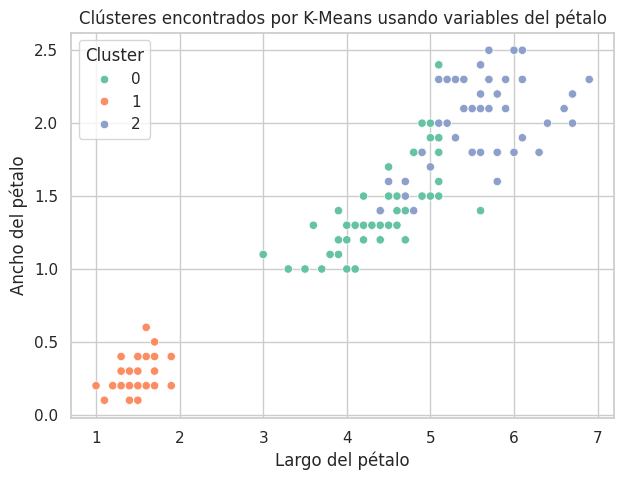

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Cluster",
    data=df_limpio,
    palette="Set2"
)
plt.title("Clústeres encontrados por K-Means usando variables del pétalo")
plt.xlabel("Largo del pétalo")
plt.ylabel("Ancho del pétalo")
plt.show()

In [ ]:
# Comparar los clústeres encontrados con las especies reales
tabla_comparacion = pd.crosstab(df_limpio["Cluster"], df_limpio["Species"])

tabla_comparacion

Species,Iris-setosa,Iris-versicolor,Iris-virginica
Cluster,,,
0,0,39,14
1,50,0,0
2,0,11,36


In [ ]:
df_limpio.groupby("Cluster")[variables_numericas].mean()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
Cluster,,,,
0,5.801887,2.673585,4.369811,1.413208
1,5.006000,3.418000,1.464000,0.244000
2,6.780851,3.095745,5.510638,1.972340


# Preguntas y respuestas: K-Means

## 1. ¿Cuál fue el número óptimo de clústeres?

El número elegido fue **k = 3**, porque el dataset Iris contiene tres grupos naturales relacionados con sus especies: `Iris-setosa`, `Iris-versicolor` e `Iris-virginica`.

Además, en el método del codo se observa una reducción importante de la inercia hasta k=3. Después de ese punto, la mejora continúa, pero es menor.

## 2. ¿Cómo se pueden describir los segmentos formados?

Los segmentos se pueden describir de la siguiente manera:

- Un clúster corresponde principalmente a `Iris-setosa`, que tiene pétalos más pequeños.
- Otro clúster agrupa flores con medidas intermedias, relacionadas principalmente con `Iris-versicolor`.
- Otro clúster agrupa flores con pétalos más largos y anchos, relacionadas principalmente con `Iris-virginica`.

La separación más clara se observa en `Iris-setosa`, mientras que `Iris-versicolor` e `Iris-virginica` pueden presentar cierta mezcla porque sus medidas son más parecidas.

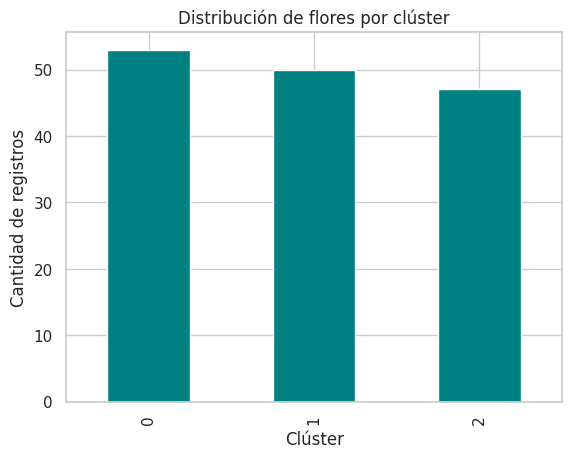

In [ ]:
df_limpio["Cluster"].value_counts().sort_index().plot(kind="bar", color="teal")

plt.title("Distribución de flores por clúster")
plt.xlabel("Clúster")
plt.ylabel("Cantidad de registros")
plt.show()

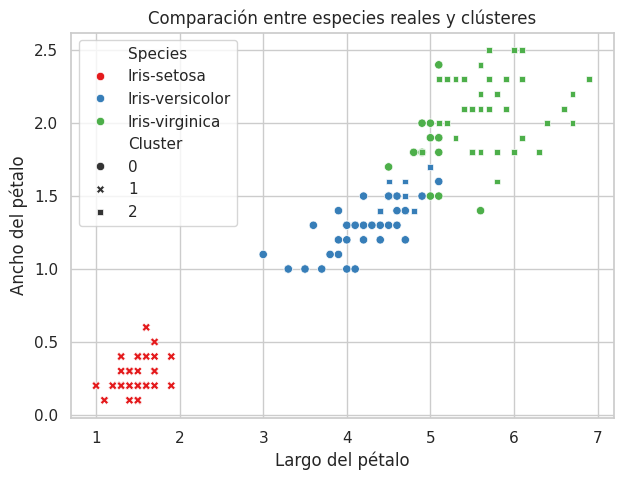

In [ ]:
plt.figure(figsize=(7,5))
sns.scatterplot(
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    style="Cluster",
    data=df_limpio,
    palette="Set1"
)
plt.title("Comparación entre especies reales y clústeres")
plt.xlabel("Largo del pétalo")
plt.ylabel("Ancho del pétalo")
plt.show()

# Preguntas y respuestas: Evaluación e interpretación

## 1. ¿Qué patrones relevantes puedes inferir?

El patrón más importante es que las medidas del pétalo permiten diferenciar mejor las especies de Iris. `Iris-setosa` forma un grupo claramente separado porque tiene pétalos más pequeños. Las especies `Iris-versicolor` e `Iris-virginica` tienen medidas más cercanas, por lo que algunos registros pueden quedar agrupados de forma similar.

## 2. ¿Qué estrategias o decisiones podrían derivarse de este análisis?

Este análisis podría utilizarse para clasificar flores de Iris según sus medidas físicas. También puede servir como base para sistemas de reconocimiento automático de especies, análisis botánico, clasificación de plantas o prácticas de aprendizaje automático. El agrupamiento permite encontrar patrones sin usar directamente las etiquetas de especie.

# Interpretación final

En esta práctica se aplicó un proceso completo de minería de datos usando el dataset Iris. Primero se cargaron los datos y se revisó su estructura. Después se realizó limpieza eliminando la columna `Id`, ya que no aportaba información útil para el modelo.

Posteriormente, se hizo un análisis exploratorio con gráficas para observar la relación entre las variables. Se identificó que las variables del pétalo son las más útiles para separar las especies.

Luego se aplicó K-Means usando los datos estandarizados. Se eligió `k = 3` porque el dataset presenta tres grupos naturales y porque el método del codo muestra una reducción importante de la inercia hasta ese punto.

Los resultados muestran que `Iris-setosa` se separa claramente, mientras que `Iris-versicolor` e `Iris-virginica` presentan mayor similitud entre ellas. En conclusión, K-Means permitió descubrir patrones relevantes en el dataset y agrupar las flores de acuerdo con sus características físicas.